In [43]:
import geopandas as gpd
import pandas as pd
import mapclassify
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LogNorm

In [44]:
data_folder = Path('/Users/michelle/Library/CloudStorage/GoogleDrive-mn3369@columbia.edu/My Drive/Fall 2026/Colloquium II/data/Marine Cable/01-CablesOwnershipList.csv')

In [45]:
from pathlib import Path

# Set the folder containing both cable datasets
data_folder = Path(
    "/Users/michelle/Library/CloudStorage/"
    "GoogleDrive-mn3369@columbia.edu/My Drive/"
    "Fall 2026/Colloquium II/data/Marine Cable"
)

# Set file paths directly inside the folder
ownership_path = data_folder / "01-CablesOwnershipList.csv"
routes_path = data_folder / "cable-geo.json"

# Verify that both paths point to files
print("Ownership file:", ownership_path.is_file())
print("Routes file:", routes_path.is_file())

Ownership file: True
Routes file: True


In [46]:
# Load ownership and status information
ownership = pd.read_csv(
    ownership_path,
    dtype={"id": "string"}
)

# Load cable routes in longitude and latitude
routes = gpd.read_file(routes_path).to_crs("EPSG:4326")

# Normalize identifiers before joining the datasets
ownership["id"] = ownership["id"].str.strip()
routes["id"] = routes["id"].astype("string").str.strip()

# Inspect available records and status labels
print(f"Ownership records: {len(ownership):,}")
print(f"Route features: {len(routes):,}")

print("\nCable status labels:")
print(ownership["status"].value_counts(dropna=False))

ownership[["id", "name", "status", "owners"]].head()

Ownership records: 697
Route features: 527

Cable status labels:
status
In service    606
Planned        91
Name: count, dtype: int64


,id,name,status,owners
0,anjana,Anjana,In service,Meta
1,bosun,Bosun,Planned,Google
2,bulikula,Bulikula,Planned,Google
3,curie,Curie,In service,Google
4,dhivaru,Dhivaru,Planned,Google


In [47]:
# Join cable routes with ownership and status information
cables = routes.merge(
    ownership[["id", "status", "owners"]],
    on="id",
    how="left",
    validate="many_to_one"
)

# Normalize status labels
source_status = (
    cables["status"]
    .astype("string")
    .str.strip()
    .str.lower()
)

# Keep unmatched or unrecognized statuses as unknown
cables["map_status"] = "Unknown"

# Identify cables recorded as operational
cables.loc[
    source_status.eq("in service").fillna(False),
    "map_status"
] = "In service"

# Identify cables recorded as planned or projected
cables.loc[
    source_status.isin(["planned", "projected"]),
    "map_status"
] = "Planned"

# Create separate layers for each status
active_cables = cables[cables["map_status"].eq("In service")].copy()
planned_cables = cables[cables["map_status"].eq("Planned")].copy()
unknown_cables = cables[cables["map_status"].eq("Unknown")].copy()

# Check how many route features belong to each layer
print(cables["map_status"].value_counts())

map_status
In service    453
Unknown        68
Planned         6
Name: count, dtype: int64


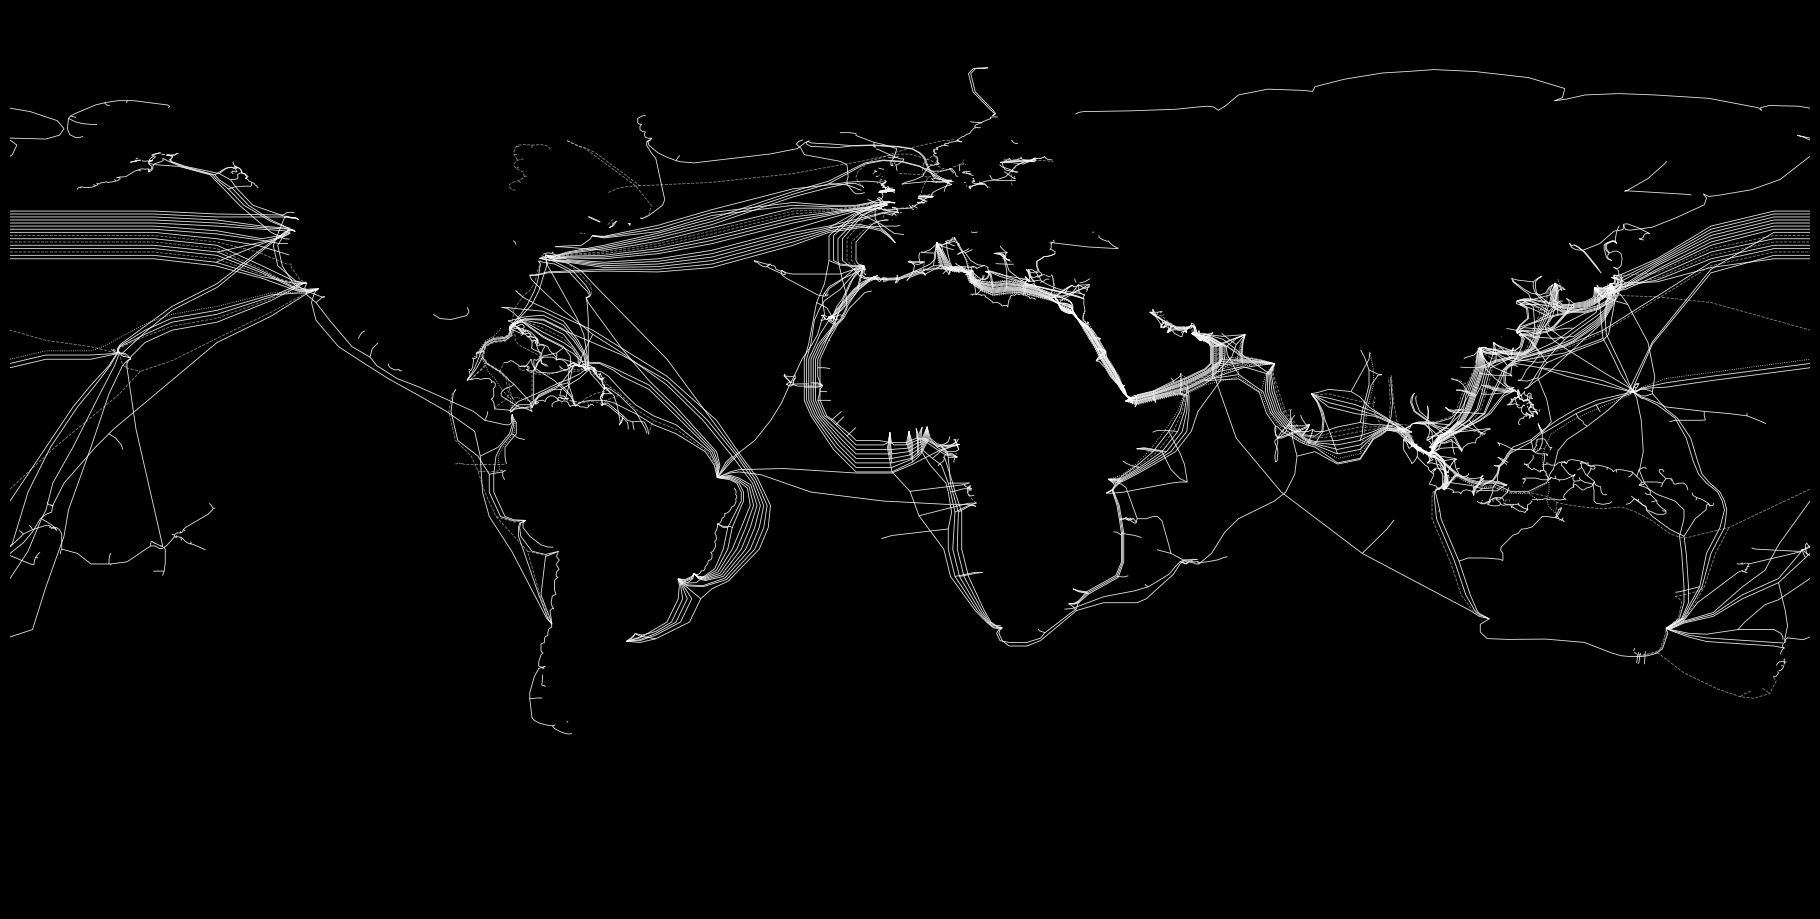

In [48]:
# Import the line symbol used in the legend
from matplotlib.lines import Line2D

# Create a black figure and map background
fig, ax = plt.subplots(
    figsize=(18, 10),
    facecolor="black"
)

ax.set_facecolor("black")


# Draw each layer with a subtle halo and a thin white line
def draw_cable_layer(layer, line_style, opacity=0.85):
    if layer.empty:
        return

    # Draw the outer halo
    layer.plot(
        ax=ax,
        color="white",
        linewidth=0.35,
        alpha=0.04,
        linestyle=line_style,
        zorder=1
    )

    # Draw the inner halo
    layer.plot(
        ax=ax,
        color="white",
        linewidth=0.6,
        alpha=0.10,
        linestyle=line_style,
        zorder=2
    )

    # Draw the main cable line
    layer.plot(
        ax=ax,
        color="white",
        linewidth=0.6,
        alpha=opacity,
        linestyle=line_style,
        zorder=3
    )


# Draw routes according to their recorded status
draw_cable_layer(unknown_cables, "--", opacity=0.45)
draw_cable_layer(active_cables, "-")
draw_cable_layer(planned_cables, ":")

# Set the global extent and hide axes
ax.set_xlim(-180, 180)
ax.set_ylim(-90, 90)
ax.set_aspect("equal")
ax.set_axis_off()

# Create a legend for the line styles
legend_handles = [
    Line2D(
        [0], [0],
        color="white",
        linewidth=0.35,
        linestyle="-",
        label="In service"
    ),
    Line2D(
        [0], [0],
        color="white",
        linewidth=0.35,
        linestyle=":",
        label="Planned"
    ),
    Line2D(
        [0], [0],
        color="white",
        linewidth=0.35,
        linestyle="--",
        alpha=0.45,
        label="Unknown status"
    )
]

# Display the map without outer padding
plt.tight_layout(pad=0)
plt.show()

In [49]:
from pathlib import Path

output_path = Path("outputs/MarineCables-bw.png")
output_path.parent.mkdir(parents=True, exist_ok=True)

fig.savefig(
    output_path,
    dpi=300,
    facecolor="black",
    transparent=False,
    bbox_inches="tight",
    pad_inches=0
)

print(f"Map saved to: {output_path.resolve()}")

Map saved to: /Users/michelle/Desktop/GIT/cdp-mapping-systems/internet/outputs/MarineCables-bw.png


In [50]:
from pathlib import Path

output_path = Path("outputs/MarineCables-bw.pdf")
output_path.parent.mkdir(parents=True, exist_ok=True)

fig.savefig(
    output_path,
    dpi=300,
    facecolor="black",
    transparent=False,
    bbox_inches="tight",
    pad_inches=0
)

print(f"Map saved to: {output_path.resolve()}")

Map saved to: /Users/michelle/Desktop/GIT/cdp-mapping-systems/internet/outputs/MarineCables-bw.pdf


In [51]:
# Inspect the existing ownership categories
print("Ownership categories:")
print(ownership["ownership_category"].value_counts(dropna=False))

# Extract individual owner names from comma-separated lists
owner_names = (
    ownership["owners"]
    .dropna()
    .str.split(",")
    .explode()
    .str.strip()
)

# Inspect company names before defining the filters
print("\nOwner names:")
print(owner_names.value_counts().to_string())

Ownership categories:
ownership_category
telco_consortium    640
hybrid               30
big_tech             26
unknown               1
Name: count, dtype: int64

Owner names:
owners
Google                                                                           34
Orange                                                                           29
Sparkle                                                                          22
BT                                                                               22
Vodafone                                                                         20
Meta                                                                             19
Singtel                                                                          19
Telekom Malaysia                                                                 19
Tata Communications                                                              19
Telkom Indonesia                                            

In [52]:
# Normalize company aliases used in the owner lists
big_tech_aliases = {
    "google": "Google",
    "meta": "Meta",
    "facebook": "Meta",
    "microsoft": "Microsoft",
    "amazon": "Amazon",
    "amazon web services": "Amazon",
    "aws": "Amazon"
}

# Set company colors and neutral ownership colors
ownership_colors = {
    "Google": "#ff00ff",
    "Meta": "#0000ff",
    "Microsoft": "#00ffff",
    "Amazon": "#ffff00",
    "Telco / consortium": "#979797",
    "Unknown": "#555555"
}


# Split owner lists and combine aliases for the same company
def parse_owners(value):
    if pd.isna(value) or not str(value).strip():
        return []

    owners = []

    for item in str(value).split(","):
        name = item.strip()

        if not name:
            continue

        normalized_name = big_tech_aliases.get(
            name.casefold(),
            name
        )

        if normalized_name.casefold() not in {
            owner.casefold() for owner in owners
        }:
            owners.append(normalized_name)

    return owners


# Identify big tech companies and shared ownership
def classify_ownership(value):
    owners = parse_owners(value)

    big_tech = [
        owner
        for owner in owners
        if owner in {"Google", "Meta", "Microsoft", "Amazon"}
    ]

    if not owners:
        category = "Unknown"
    elif not big_tech:
        category = "Telco / consortium"
    elif len(owners) == 1:
        category = "Big tech only"
    else:
        category = "Hybrid"

    return pd.Series({
        "owner_list": owners,
        "big_tech_companies": big_tech,
        "owner_count": len(owners),
        "is_hybrid": bool(big_tech) and len(owners) > 1,
        "ownership_type": category
    })


# Add ownership classifications to the geographic cable dataset
ownership_details = cables["owners"].apply(classify_ownership)

cables = cables.drop(
    columns=ownership_details.columns,
    errors="ignore"
).join(ownership_details)

# Inspect the resulting categories
print(cables["ownership_type"].value_counts())

display(
    cables[
        [
            "name",
            "owners",
            "big_tech_companies",
            "ownership_type",
            "map_status"
        ]
    ].head(10)
)

ownership_type
Telco / consortium    423
Unknown                69
Hybrid                 28
Big tech only           7
Name: count, dtype: int64


,name,owners,big_tech_companies,ownership_type,map_status
0,Sagres,Altice Portugal,[],Telco / consortium,In service
1,Continente-Madeira,Altice Portugal,[],Telco / consortium,In service
2,Almería-Melilla (ALME),Telefonica,[],Telco / consortium,In service
3,Roquetas-Melilla (CAM),Telefonica,[],Telco / consortium,In service
4,N0r5ke Viking 2,NaN,[],Unknown,Unknown
5,Philippine Domestic Submarine Cable Network (P...,"Eastern Telecom, Globe Telecom, Infinivan Inc.",[],Telco / consortium,In service
6,Groix 4,Orange,[],Telco / consortium,In service
7,Thetis,Vodafone,[],Telco / consortium,In service
8,JUNO,Seren Juno,[],Telco / consortium,In service
9,Bridge One,NaN,[],Unknown,Unknown


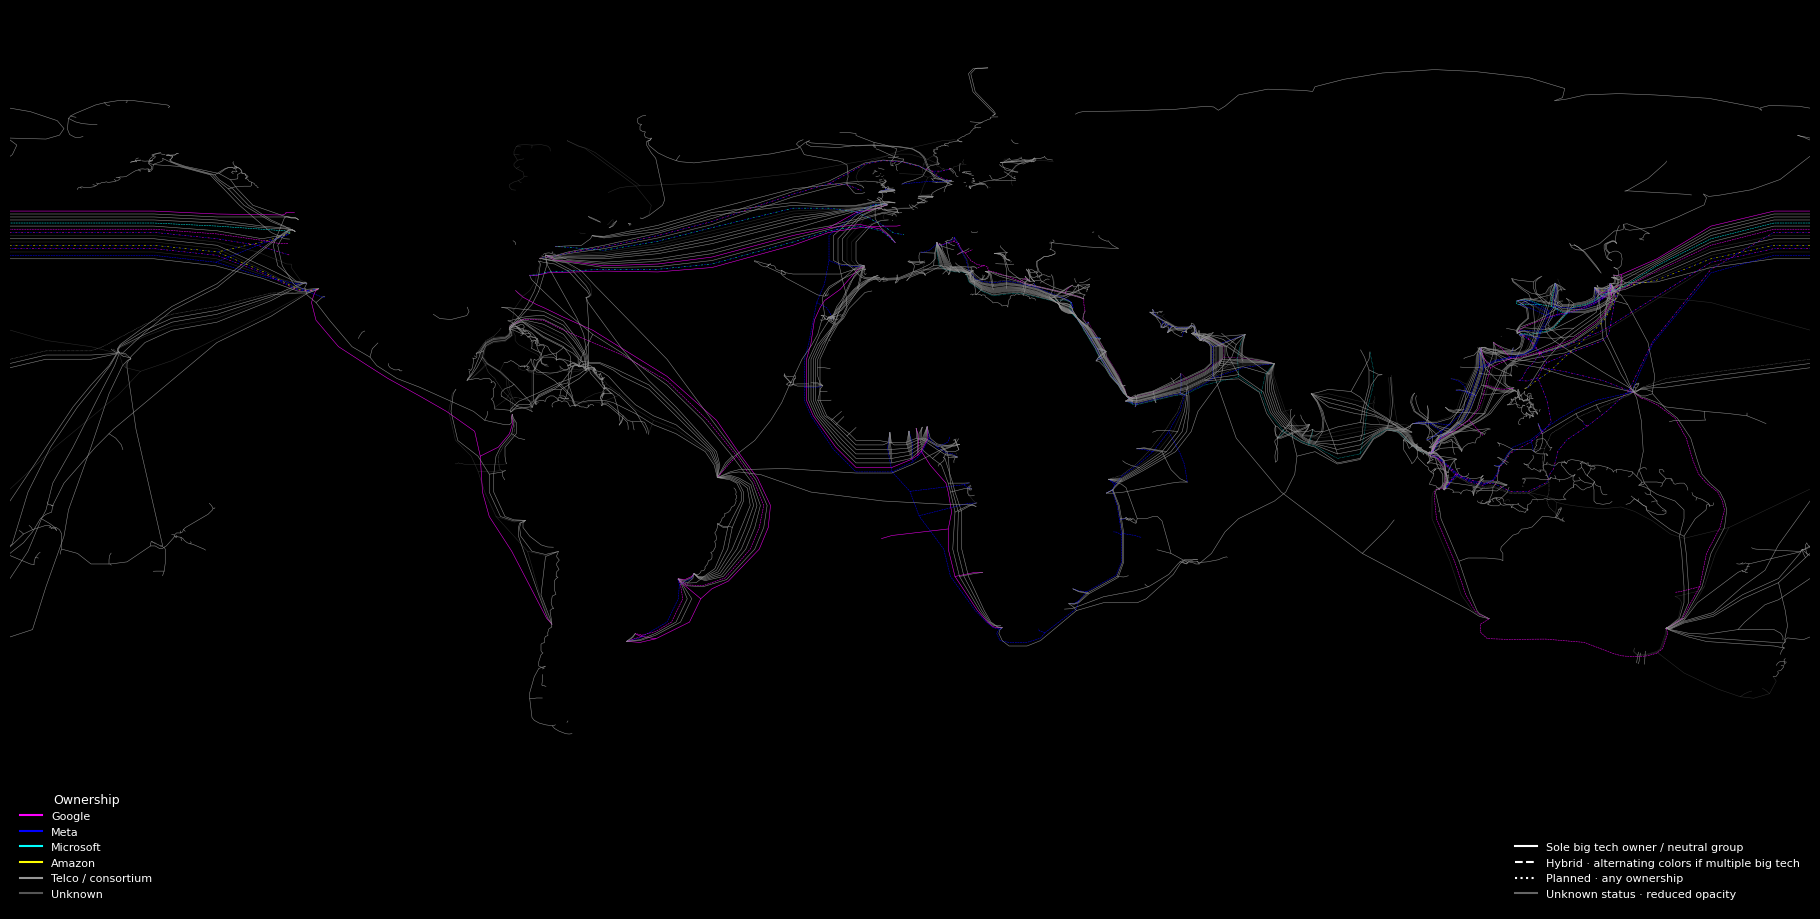

In [53]:
from matplotlib.lines import Line2D

# Create a black figure and map background
fig, ax = plt.subplots(
    figsize=(18, 10),
    facecolor="black"
)

ax.set_facecolor("black")


# Extract line geometries from each cable route
def get_route_lines(geometry):
    if geometry is None or geometry.is_empty:
        return []

    if geometry.geom_type == "LineString":
        return [geometry]

    if geometry.geom_type in {"MultiLineString", "GeometryCollection"}:
        lines = []

        for part in geometry.geoms:
            lines.extend(get_route_lines(part))

        return lines

    return []


# Draw a single-color route with a subtle halo
def draw_single_color(x, y, color, line_style, opacity):
    # Outer halo
    ax.plot(
        x, y,
        color=color,
        linewidth=0.35,
        alpha=0.04,
        linestyle=line_style,
        zorder=1
    )

    # Inner halo
    ax.plot(
        x, y,
        color=color,
        linewidth=0.6,
        alpha=0.10,
        linestyle=line_style,
        zorder=2
    )

    # Main route
    ax.plot(
        x, y,
        color=color,
        linewidth=0.35,
        alpha=opacity,
        linestyle=line_style,
        zorder=3
    )


# Alternate company colors using interleaved dash patterns
def draw_shared_colors(x, y, route_colors, planned, opacity):
    # Use short dotted marks for planned cables
    # Use longer dashed marks for other hybrid cables
    dash_length = 0.8 if planned else 4
    gap_length = 2

    step = dash_length + gap_length
    cycle_length = step * len(route_colors)

    for index, color in enumerate(route_colors):
        dash_style = (
            index * step,
            (dash_length, cycle_length - dash_length)
        )

        draw_single_color(
            x,
            y,
            color,
            dash_style,
            opacity
        )


# Draw every cable using its owners and recorded status
for _, cable in cables.iterrows():
    companies = cable["big_tech_companies"]
    planned = cable["map_status"] == "Planned"
    unknown_status = cable["map_status"] == "Unknown"

    # Reduce visibility when the operational status is unknown
    opacity = 0.4 if unknown_status else 0.9

    # Select company colors or a neutral ownership color
    if companies:
        route_colors = [
            ownership_colors[company]
            for company in companies
        ]
    else:
        route_colors = [
            ownership_colors[cable["ownership_type"]]
        ]

    # Planned routes take priority over the ownership dash style
    if planned:
        line_style = ":"
    elif cable["is_hybrid"]:
        line_style = "--"
    else:
        line_style = "-"

    # Draw each part of the geographic route
    for line in get_route_lines(cable.geometry):
        x, y = line.xy

        if len(route_colors) > 1:
            draw_shared_colors(
                x,
                y,
                route_colors,
                planned,
                opacity
            )
        else:
            draw_single_color(
                x,
                y,
                route_colors[0],
                line_style,
                opacity
            )


# Set the global extent and hide axes
ax.set_xlim(-180, 180)
ax.set_ylim(-90, 90)
ax.set_aspect("equal")
ax.set_axis_off()

# Explain the ownership colors
color_handles = [
    Line2D(
        [0], [0],
        color=color,
        linewidth=1.5,
        label=label
    )
    for label, color in ownership_colors.items()
]

color_legend = ax.legend(
    handles=color_handles,
    title="Ownership",
    loc="lower left",
    frameon=False,
    labelcolor="white",
    fontsize=8,
    title_fontsize=9
)

color_legend.get_title().set_color("white")
ax.add_artist(color_legend)

# Explain the ownership and status line styles
style_handles = [
    Line2D(
        [0], [0],
        color="white",
        linestyle="-",
        label="Sole big tech owner / neutral group"
    ),
    Line2D(
        [0], [0],
        color="white",
        linestyle="--",
        label="Hybrid · alternating colors if multiple big tech"
    ),
    Line2D(
        [0], [0],
        color="white",
        linestyle=":",
        label="Planned · any ownership"
    ),
    Line2D(
        [0], [0],
        color="white",
        alpha=0.4,
        label="Unknown status · reduced opacity"
    )
]

style_legend = ax.legend(
    handles=style_handles,
    loc="lower right",
    frameon=False,
    labelcolor="white",
    fontsize=8
)

# Display the complete map
plt.tight_layout(pad=0)
plt.show()

In [54]:
from pathlib import Path

output_path = Path("outputs/MarineCables.png")
output_path.parent.mkdir(parents=True, exist_ok=True)

fig.savefig(
    output_path,
    dpi=300,
    facecolor="black",
    transparent=False,
    bbox_inches="tight",
    pad_inches=0
)

print(f"Map saved to: {output_path.resolve()}")

Map saved to: /Users/michelle/Desktop/GIT/cdp-mapping-systems/internet/outputs/MarineCables.png


In [55]:
from pathlib import Path

output_path = Path("outputs/MarineCables.pdf")
output_path.parent.mkdir(parents=True, exist_ok=True)

fig.savefig(
    output_path,
    dpi=300,
    facecolor="black",
    transparent=False,
    bbox_inches="tight",
    pad_inches=0
)

print(f"Map saved to: {output_path.resolve()}")

Map saved to: /Users/michelle/Desktop/GIT/cdp-mapping-systems/internet/outputs/MarineCables.pdf
